# Лабораторная работа 8. Законы масштабирования и Mixture of Experts (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 3:** предобучение, оптимизация, масштабирование

**Цель.** Получить собственные законы масштабирования в миниатюре, найти compute-optimal соотношение размера модели и числа токенов и исследовать разреженные MoE-модели.

**Что нужно сдать:**
1. Серию обученных моделей разного размера при нескольких бюджетах токенов.
2. Аппроксимацию \(L(N, D) = E + A/N^\alpha + B/D^\beta\) с bootstrap-интервалами для \(\alpha, \beta\).
3. IsoFLOP-анализ и оценку compute-optimal отношения \(D/N\) в сравнении с Chinchilla.
4. MoE-слой с top-2 роутингом и балансирующим loss; сравнение с плотной моделью при равном числе активных параметров.
5. Анализ коллапса роутинга и специализации экспертов.

**Теория.** При ограничении бюджета \(C = 6ND\) минимизация \(L(N, D) = E + A N^{-\alpha} + B D^{-\beta}\) даёт
\[
N_{opt}(C) = G\left(\frac{C}{6}\right)^{\frac{\beta}{\alpha+\beta}},\qquad
D_{opt}(C) = G^{-1}\left(\frac{C}{6}\right)^{\frac{\alpha}{\alpha+\beta}},\qquad
G = \left(\frac{\alpha A}{\beta B}\right)^{\frac{1}{\alpha+\beta}} .
\]
В работе Hoffmann et al. (2022) \(\alpha \approx 0.34\), \(\beta \approx 0.28\), что даёт около 20 токенов на параметр.

**Балансирующий loss (Switch Transformer).** Для \(E\) экспертов, доли токенов \(f_i\), направленных к эксперту \(i\), и средней вероятности роутера \(P_i\):
\[
\mathcal{L}_{aux} = E\sum_{i=1}^{E} f_i P_i ,
\]
минимум (равный 1) достигается при равномерной загрузке.

In [ ]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.14.1+cpu, device=cpu, FAST_DEV_RUN=True


In [ ]:
# ==== Эталонный mini-GPT (решение ЛР 6), используется как готовый модуль ====
from dataclasses import dataclass, asdict

class CharTokenizer:
    def __init__(self, text):
        self.chars = sorted(set(text)); self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.vocab_size = len(self.chars)
    def encode(self, s): return [self.stoi[c] for c in s if c in self.stoi]
    def decode(self, ids): return "".join(self.chars[i] for i in ids)

@dataclass
class GPTConfig:
    vocab_size: int = 65
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    dropout: float = 0.0

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.eps = eps; self.weight = nn.Parameter(torch.ones(d))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def rope_cache(T, d_head, base=10000.0, device="cpu", scale=1.0):
    inv = 1.0 / (base ** (torch.arange(0, d_head, 2, device=device).float() / d_head))
    t = torch.arange(T, device=device).float() / scale
    ang = torch.outer(t, inv)                        # (T, d_head/2)
    return ang.cos(), ang.sin()

def apply_rope(x, cos, sin):                         # x: (B, H, T, d_head)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)
    return out.flatten(-2)

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n_head, self.d_head = cfg.n_head, cfg.n_embd // cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=False)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)
    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, self.d_head).transpose(1, 2) for t in (q, k, v))
        q, k = apply_rope(q, cos[:T], sin[:T]), apply_rope(k, cos[:T], sin[:T])
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(y.transpose(1, 2).reshape(B, T, C))

class SwiGLU(nn.Module):
    def __init__(self, d, hidden):
        super().__init__()
        self.w1, self.w3 = nn.Linear(d, hidden, bias=False), nn.Linear(d, hidden, bias=False)
        self.w2 = nn.Linear(hidden, d, bias=False)
    def forward(self, x): return self.w2(F.silu(self.w1(x)) * self.w3(x))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n1, self.attn = RMSNorm(cfg.n_embd), CausalSelfAttention(cfg)
        self.n2, self.mlp = RMSNorm(cfg.n_embd), SwiGLU(cfg.n_embd, int(8 * cfg.n_embd / 3))
    def forward(self, x, cos, sin):
        x = x + self.attn(self.n1(x), cos, sin)
        return x + self.mlp(self.n2(x))

class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.norm = RMSNorm(cfg.n_embd)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.head.weight = self.wte.weight                    # weight tying
        cos, sin = rope_cache(4 * cfg.block_size, cfg.n_embd // cfg.n_head)
        self.register_buffer("cos", cos, persistent=False); self.register_buffer("sin", sin, persistent=False)
        self.apply(self._init)
        for n, p in self.named_parameters():                  # масштабирование выходных проекций по глубине
            if n.endswith("proj.weight") or n.endswith("w2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * cfg.n_layer))
    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)
    def forward(self, idx, targets=None):
        x = self.wte(idx)
        for b in self.blocks: x = b(x, self.cos, self.sin)
        logits = self.head(self.norm(x))
        loss = None if targets is None else F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        return logits, loss
    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.cfg.block_size:])
            probs = F.softmax(logits[:, -1] / temperature, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def get_batch(data, block_size, batch_size, device=DEVICE):
    ix = torch.randint(len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i:i + block_size] for i in ix]); y = torch.stack([data[i + 1:i + 1 + block_size] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model, data, block_size, batch_size=32, iters=20):
    model.eval(); losses = [model(*get_batch(data, block_size, batch_size))[1].item() for _ in range(iters)]
    model.train(); return float(np.mean(losses))

def train_lm(model, train_data, val_data, steps, lr=3e-3, batch_size=32, warmup=50, log_every=100):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))
    hist = []
    for s in range(steps):
        x, y = get_batch(train_data, model.cfg.block_size, batch_size)
        _, loss = model(x, y); opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if s % log_every == 0 or s == steps - 1:
            hist.append((s, loss.item(), estimate_loss(model, val_data, model.cfg.block_size)))
    return hist

def get_reference_gpt(text, cfg=None, steps=None, name=None):
    """Загружает или обучает эталонную символьную модель на тексте."""
    tok = CharTokenizer(text)
    data = torch.tensor(tok.encode(text), dtype=torch.long)
    n = int(0.9 * len(data)); train_data, val_data = data[:n], data[n:]
    cfg = cfg or (GPTConfig(tok.vocab_size, 64, 2, 4, 64) if FAST_DEV_RUN else GPTConfig(tok.vocab_size, 256, 6, 6, 384))
    name = name or f"ref_gpt_L{cfg.n_layer}_d{cfg.n_embd}_T{cfg.block_size}.pt"
    path = ARTIFACTS / name
    model = GPT(cfg).to(DEVICE)
    if path.exists():
        model.load_state_dict(torch.load(path, map_location=DEVICE))
    else:
        train_lm(model, train_data, val_data, steps or (300 if FAST_DEV_RUN else 5000))
        torch.save(model.state_dict(), path)
    return model, tok, train_data, val_data

In [ ]:
text = load_shakespeare(); tok = CharTokenizer(text)
data = torch.tensor(tok.encode(text)); ntr = int(0.9 * len(data)); train_data, val_data = data[:ntr], data[ntr:]
T_CTX, BATCH = 64, 32
TOKENS_PER_STEP = T_CTX * BATCH

## 1. Серия моделей

Используйте эталонный GPT с фиксированной глубиной и варьируйте ширину. Число параметров \(N\) считайте **без эмбеддингов** (как у Kaplan et al.). Для каждой модели оцените val loss при нескольких бюджетах токенов \(D\).

Корректная процедура требует отдельного запуска с полным косинусным расписанием для каждой пары \((N, D)\). В `FAST_DEV_RUN` используется упрощение: один запуск с постоянным LR и оценкой в промежуточных точках. Оно завышает loss для малых \(D\) (не было фазы спада LR), и это надо учесть при интерпретации.

In [ ]:
WIDTHS = [32, 48, 64, 96, 128] if FAST_DEV_RUN else [32, 48, 64, 96, 128, 192, 256, 384]
STEP_BUDGETS = [50, 100, 200, 400] if FAST_DEV_RUN else [250, 500, 1000, 2000, 4000]
SEPARATE_RUNS = not FAST_DEV_RUN
N_LAYER = 2 if FAST_DEV_RUN else 4

def non_embedding_params(model):
    return sum(p.numel() for n, p in model.named_parameters() if not n.startswith(("wte", "head")))

def run_scaling(width, budgets, lr=3e-3, separate=False):
    """Возвращает (N, список (D, val_loss))."""
    cfg = GPTConfig(tok.vocab_size, T_CTX, N_LAYER, max(1, width // 16), width)
    # (при separate — отдельный train_lm на каждый бюджет; иначе один запуск с постоянным LR и оценками)
    set_seed()
    probe = GPT(cfg)
    N = non_embedding_params(probe)

    res = []
    if separate:
        for steps in budgets:
            set_seed()
            model = GPT(cfg).to(DEVICE)
            train_lm(
                model, train_data, val_data, steps,
                lr=lr, batch_size=BATCH,
                warmup=min(50, max(1, steps // 10)),
                log_every=max(steps, 1),
            )
            L = estimate_loss(model, val_data, T_CTX, batch_size=BATCH, iters=20)
            res.append((steps * TOKENS_PER_STEP, L))
    else:
        set_seed()
        model = GPT(cfg).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=lr,
                                betas=(0.9, 0.95), weight_decay=0.1)
        max_steps = max(budgets)
        budget_set = set(budgets)
        for s in range(max_steps):
            x, y = get_batch(train_data, T_CTX, BATCH)
            _, loss = model(x, y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            if (s + 1) in budget_set:
                L = estimate_loss(model, val_data, T_CTX, batch_size=BATCH, iters=20)
                res.append(((s + 1) * TOKENS_PER_STEP, L))
    return N, res

t0 = time.time(); points = []
for w in WIDTHS:
    N, res = run_scaling(w, STEP_BUDGETS, separate=SEPARATE_RUNS)
    for D, L in res: points.append((N, D, L))
    print(f"d={w:4d}  N={N:>9,}  " + "  ".join(f"D={D:,}: {L:.3f}" for D, L in res))
points = np.array(points); print(f"{time.time() - t0:.0f} c")
np.save(ARTIFACTS / "lab08_points.npy", points)

d=  32  N=   24,672  D=102,400: 2.846  D=204,800: 2.458  D=409,600: 2.270  D=819,200: 2.104
d=  48  N=   55,536  D=102,400: 2.776  D=204,800: 2.392  D=409,600: 2.219  D=819,200: 2.028
d=  64  N=   98,368  D=102,400: 2.659  D=204,800: 2.371  D=409,600: 2.123  D=819,200: 2.005
d=  96  N=  221,664  D=102,400: 2.410  D=204,800: 2.222  D=409,600: 2.060  D=819,200: 1.921
d= 128  N=  393,600  D=102,400: 2.512  D=204,800: 2.308  D=409,600: 2.138  D=819,200: 1.957
289 c


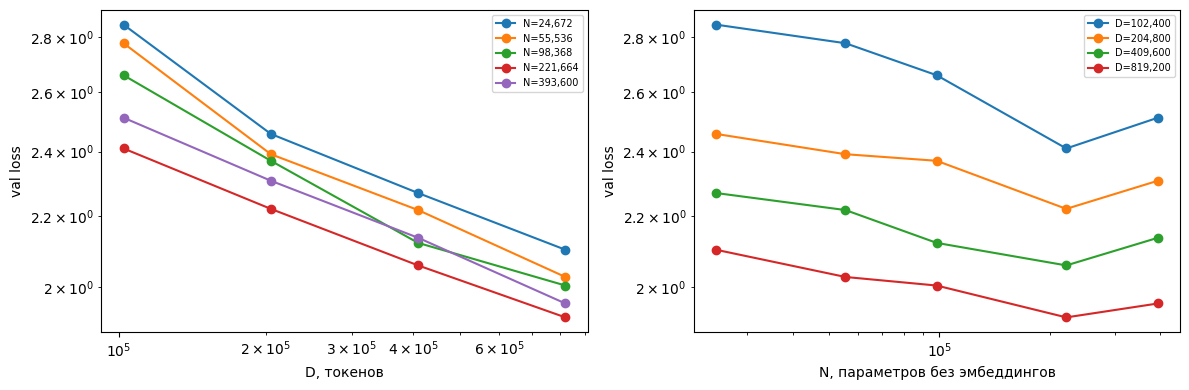

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for N in np.unique(points[:, 0]):
    p = points[points[:, 0] == N]; ax[0].plot(p[:, 1], p[:, 2], "o-", label=f"N={int(N):,}")
for D in np.unique(points[:, 1]):
    p = points[points[:, 1] == D]; ax[1].plot(p[:, 0], p[:, 2], "o-", label=f"D={int(D):,}")
for a, xl in zip(ax, ["D, токенов", "N, параметров без эмбеддингов"]):
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel(xl); a.set_ylabel("val loss"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 2. Аппроксимация \(L(N, D)\) и bootstrap

Подберите $((E, A, \alpha, B, \beta))$ методом наименьших квадратов в пространстве $(\log L)$ (`scipy.optimize.least_squares`, ограничения $(E, A, B > 0)$, $(0 < \alpha, \beta < 2)$), начиная с нескольких начальных точек. Затем выполните bootstrap: 200 раз перевыберите точки с возвращением и постройте 90%-интервалы для $(\alpha)$ и $(\beta)$.

In [ ]:
from scipy.optimize import least_squares

def law(params, N, D):
    E, A, alpha, B, beta = params
    return E + A / N ** alpha + B / D ** beta

def fit_law(pts, n_starts=20, seed=0):
    N, D, L = pts[:, 0], pts[:, 1], pts[:, 2]
    rng = np.random.default_rng(seed)
    lo = np.array([-10, -10, 1e-3, -10, 1e-3])
    hi = np.array([ 10,  20, 2-1e-3, 20, 2-1e-3])

    def res(th):
        p = (np.exp(th[0]), np.exp(th[1]), th[2], np.exp(th[3]), th[4])
        return np.log(law(p, N, D)) - np.log(L)

    best = None
    for k in range(n_starts):
        th0 = np.array([np.log(rng.uniform(0.1, 5)),
                        np.log(rng.uniform(10, 1e6)),
                        rng.uniform(0.05, 1.5),
                        np.log(rng.uniform(10, 1e6)),
                        rng.uniform(0.05, 1.5)])
        th0 = np.clip(th0, lo + 1e-6, hi - 1e-6)
        try:
            s = least_squares(res, th0, bounds=(lo, hi),
                              xtol=1e-12, ftol=1e-12, max_nfev=5000)
        except Exception:
            continue
        if np.isfinite(s.cost) and (best is None or s.cost < best[0]):
            best = (s.cost, s.x)

    c, th = best
    params = (float(np.exp(th[0])), float(np.exp(th[1])), float(th[2]),
              float(np.exp(th[3])), float(th[4]))
    return params, float(c)

params, cost = fit_law(points)
E, A, alpha, B, beta = params
print(f"E={E:.3f}, A={A:.3g}, α={alpha:.3f}, B={B:.3g}, β={beta:.3f}, cost={cost:.2e}")
pred = law(params, points[:, 0], points[:, 1])
print("средняя относительная ошибка:", np.mean(np.abs(pred - points[:, 2]) / points[:, 2]).round(4))

E=1.420, A=34.5, α=0.466, B=175, β=0.445, cost=5.53e-03
средняя относительная ошибка: 0.0188


In [ ]:
# TODO: ваш код (bootstrap 200 (в FAST 50) повторов, 90% интервалы для α и β)
n_boot = 200 if FAST_DEV_RUN else 200
rng = np.random.default_rng(123)
ab = []
M = len(points)
for _ in range(n_boot):
    idx = rng.integers(0, M, M)
    try:
        p, _ = fit_law(points[idx], n_starts=3, seed=int(rng.integers(1e6)))
        ab.append((p[2], p[4]))
    except Exception:
        pass
ab = np.array(ab)

for i, name in enumerate(["α", "β"]):
    lo, hi = np.percentile(ab[:, i], [5, 95])
    print(f"{name}: mean={ab[:, i].mean():.3f}, 90% CI=[{lo:.3f}, {hi:.3f}] "
          f"(n={len(ab)})")

α: mean=0.515, 90% CI=[0.065, 0.972] (n=200)
β: mean=0.452, 90% CI=[0.140, 0.801] (n=200)


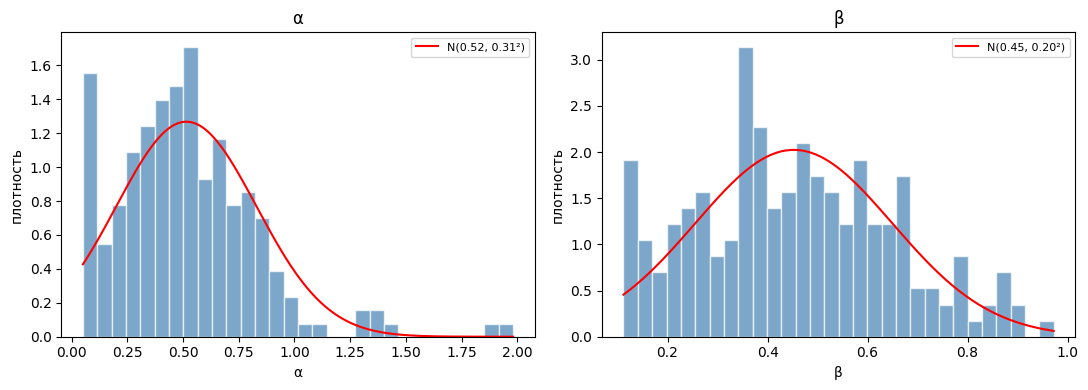

In [ ]:
import matplotlib.pyplot as plt
from scipy import stats

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for i, name in enumerate(["α", "β"]):
    a = ax[i]
    v = ab[:, i]
    a.hist(v, bins=30, alpha=0.7, color="steelblue", edgecolor="white", density=True)

    mu, sd = v.mean(), v.std()
    xs = np.linspace(v.min(), v.max(), 200)
    a.plot(xs, stats.norm.pdf(xs, mu, sd), "r-", lw=1.5,
           label=f"N({mu:.2f}, {sd:.2f}²)")

    a.set_title(name)
    a.set_xlabel(name); a.set_ylabel("плотность"); a.legend(fontsize=8)

plt.tight_layout(); plt.savefig(ARTIFACTS / "lab08_bootstrap_hist.png", dpi=150); plt.show()

## 3. IsoFLOP и compute-optimal соотношение

1. Для нескольких бюджетов \(C\) постройте \(L(N, C/6N)\) как функцию \(N\) (IsoFLOP-кривые) по подобранному закону и найдите минимум.
2. Сравните численный минимум с аналитической формулой \(N_{opt}(C)\) из введения.
3. Посчитайте оптимальное число токенов на параметр \(D_{opt}/N_{opt}\) и сравните с ~20 у Chinchilla. Объясните расхождение: символьная токенизация, маленькие модели, вклад эмбеддингов, упрощённая процедура.

In [ ]:
def compute_optimal(C):
    G = (alpha * A / (beta * B)) ** (1.0 / (alpha + beta))
    N = G * (C / 6) ** (beta / (alpha + beta))
    D = (C / 6) ** (alpha / (alpha + beta)) / G
    return N, D, D / N

# численный минимум IsoFLOP
def isoflop_min(C, N_grid=None):
    if N_grid is None:
        N_grid = np.logspace(np.log10(1e2), np.log10(1e8), 2000)
    D_grid = C / (6 * N_grid)
    L_grid = E + A * N_grid ** (-alpha) + B * D_grid ** (-beta)
    i = np.argmin(L_grid)
    return N_grid[i], D_grid[i], D_grid[i] / N_grid[i], L_grid[i]

C_real = 6 * points[:, 0] * points[:, 1]
C_values = np.logspace(np.log10(C_real.min()), np.log10(C_real.max()), 6)

print(" C              N_num*        N_anal*       D/N_num   D/N_anal   L_min")
print("-" * 80)
rows = []
for C in C_values:
    Nn, Dn, rn, Ln = isoflop_min(C)
    Na, Da, ra = compute_optimal(C)
    rows.append((C, Nn, Dn, rn, Na, Da, ra, Ln))
    print(f"{C:9.2e}  {Nn:11.3e}  {Na:11.3e}  {rn:8.2f}  {ra:8.2f}  {Ln:.3f}")

 C              N_num*        N_anal*       D/N_num   D/N_anal   L_min
--------------------------------------------------------------------------------
 1.52e+10    6.917e+03    6.894e+03     52.80     53.15  2.569
 4.00e+10    1.107e+04    1.107e+04     54.41     54.37  2.341
 1.05e+11    1.783e+04    1.778e+04     55.29     55.61  2.159
 2.78e+11    2.853e+04    2.855e+04     56.97     56.88  2.012
 7.34e+11    4.595e+04    4.584e+04     57.89     58.18  1.895
 1.93e+12    7.352e+04    7.361e+04     59.65     59.51  1.801


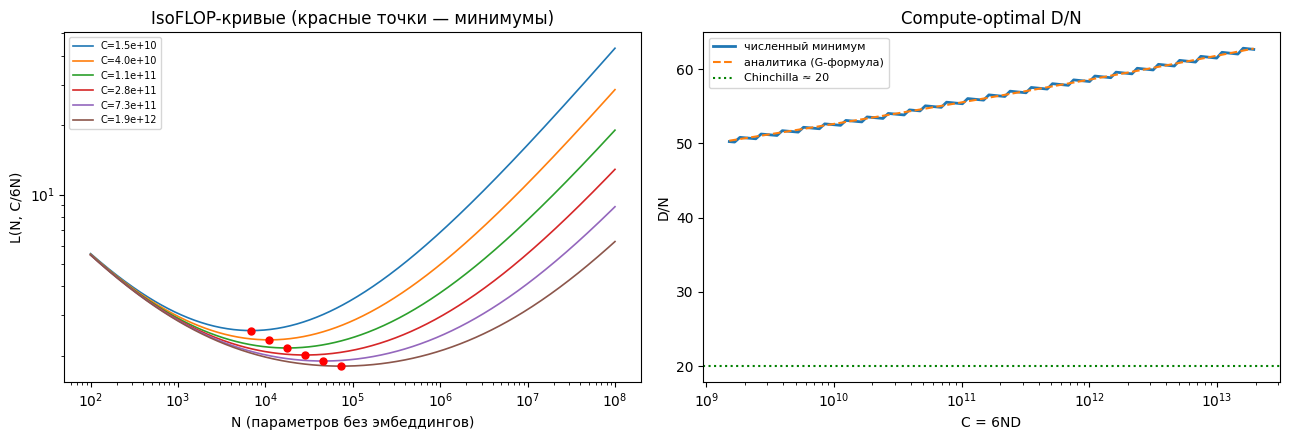

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# IsoFLOP-кривые L(N) при фиксированных C
N_grid = np.logspace(2, 8, 400)
for C in C_values:
    D_grid = C / (6 * N_grid)
    L_grid = E + A * N_grid ** (-alpha) + B * D_grid ** (-beta)
    N_opt, _, _, L_opt = isoflop_min(C)
    ax[0].plot(N_grid, L_grid, lw=1.2, label=f"C={C:.1e}")
    ax[0].scatter([N_opt], [L_opt], color="red", zorder=5, s=25)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("N (параметров без эмбеддингов)")
ax[0].set_ylabel("L(N, C/6N)")
ax[0].set_title("IsoFLOP-кривые (красные точки — минимумы)")
ax[0].legend(fontsize=7)

# D/N как функция C: численный vs аналитический
Cs = np.logspace(np.log10(C_values.min() * 0.1),
                 np.log10(C_values.max() * 10), 100)
ratio_num = np.array([isoflop_min(C)[2] for C in Cs])
ratio_ana = np.array([compute_optimal(C)[2] for C in Cs])
ax[1].plot(Cs, ratio_num, "-", lw=2, label="численный минимум")
ax[1].plot(Cs, ratio_ana, "--", lw=1.5, label="аналитика (G-формула)")
ax[1].axhline(20, color="green", ls=":", lw=1.5, label="Chinchilla ≈ 20")
ax[1].set_xscale("log")
ax[1].set_xlabel("C = 6ND"); ax[1].set_ylabel("D/N")
ax[1].set_title("Compute-optimal D/N"); ax[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(ARTIFACTS / "lab08_isoflop.png", dpi=150)
plt.show()

## 4. Mixture of Experts

Реализуйте MoE-FFN с \(E\) экспертами (каждый — SwiGLU со скрытым размером \(h_e\)) и top-\(k\) роутингом:
1. логиты роутера \(z = xW_r\), вероятности \(p = \mathrm{softmax}(z)\);
2. выбор top-\(k\) экспертов, веса — перенормированные вероятности выбранных экспертов;
3. балансирующий loss \(\mathcal{L}_{aux} = E\sum_i f_i P_i\), где \(f_i\) — доля назначений токенов эксперту \(i\) (с учётом всех \(k\) выборов, нормированная на \(k\)), \(P_i\) — средняя вероятность.

Плотная модель с FFN-скрытым размером \(h\) и MoE с \(E = 4\), \(k = 2\), \(h_e = h/2\) имеют **одинаковое число активных параметров** на токен, но у MoE вдвое больше общих параметров FFN.

In [ ]:
class Expert(nn.Module):
    def __init__(self, d, h):
        super().__init__(); self.w1, self.w3, self.w2 = nn.Linear(d, h, bias=False), nn.Linear(d, h, bias=False), nn.Linear(h, d, bias=False)
    def forward(self, x): return self.w2(F.silu(self.w1(x)) * self.w3(x))

class MoE(nn.Module):
    def __init__(self, d, n_experts=4, hidden=None, k=2):
        super().__init__()
        self.E, self.k = n_experts, k
        self.router = nn.Linear(d, n_experts, bias=False)
        self.experts = nn.ModuleList([Expert(d, hidden or int(8 * d / 3) // 2) for _ in range(n_experts)])
        self.aux, self.last_assign = torch.tensor(0.0), None
    def forward(self, x):
        B, T, C = x.shape
        xf = x.reshape(-1, C)
        M = xf.shape[0]

        # Логиты и вероятности роутера
        logits = self.router(xf)
        probs = F.softmax(logits, dim=-1)

        # Выбор top-k и перенормировка весов
        topv, topi = probs.topk(self.k, dim=-1)
        topv = topv / topv.sum(-1, keepdim=True)

        # Балансирующий loss (Switch Transformer)
        onehot = F.one_hot(topi, self.E).float().sum(dim=1)
        f = onehot.mean(dim=0) / self.k
        P = probs.mean(dim=0)

        aux = self.E * (f * P).sum()
        self.aux = aux
        self.last_assign = topi

        # Прогон токенов через экспертов
        out = torch.zeros_like(xf)
        for e in range(self.E):
            mask = (topi == e)
            if not mask.any():
                continue
            token_idx, slot_idx = mask.nonzero(as_tuple=True)
            w = topv[token_idx, slot_idx]

            # Вход для эксперта, выход взвешиваем на w
            y = self.experts[e](xf[token_idx]) * w.unsqueeze(-1)

            # Аккумулируем вклад
            out.index_add_(0, token_idx, y)

        return out.view(B, T, C)

def make_model(kind, width=128):
    cfg = GPTConfig(tok.vocab_size, T_CTX, N_LAYER, 4, width)
    set_seed(); m = GPT(cfg)
    if kind.startswith("moe"):
        for b in m.blocks: b.mlp = MoE(width)
    elif kind == "dense-small":
        for b in m.blocks: b.mlp = SwiGLU(width, int(8 * width / 3) // 2 * 2)   # та же активная ширина, что top-2 × h/2
    return m.to(DEVICE)

def train_moe(model, steps, aux_coef=0.01, lr=3e-3):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1); hist = []
    for s in range(steps):
        x, y = get_batch(train_data, T_CTX, BATCH); loss = model(x, y)[1]
        aux = sum(b.mlp.aux for b in model.blocks if isinstance(b.mlp, MoE)) if aux_coef else 0.0
        opt.zero_grad(); (loss + aux_coef * aux).backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        if s % 25 == 0 or s == steps - 1:
            loads = [torch.bincount(b.mlp.last_assign.flatten(), minlength=4).float() / b.mlp.last_assign.numel()
                     for b in model.blocks if isinstance(b.mlp, MoE)]
            hist.append((s, loss.item(), [l.tolist() for l in loads]))
    return hist

MOE_STEPS = 300 if FAST_DEV_RUN else 3000
runs = {}
for name, kind, coef in [("dense (активные = MoE)", "dense-small", 0), ("MoE top-2, aux=0.01", "moe", 0.01), ("MoE top-2, без aux", "moe", 0.0)]:
    m = make_model(kind); t0 = time.time(); h = train_moe(m, MOE_STEPS, aux_coef=coef)
    total = sum(p.numel() for p in m.parameters())
    runs[name] = (m, h); print(f"{name:25s} params={total:,}  val={estimate_loss(m, val_data, T_CTX, iters=20):.3f}  ({time.time() - t0:.0f} c)")

dense (активные = MoE)    params=401,152  val=1.971  (56 c)
MoE top-2, aux=0.01       params=663,296  val=1.912  (64 c)
MoE top-2, без aux        params=663,296  val=1.911  (64 c)


### Коллапс роутинга и специализация

1. Постройте динамику загрузки экспертов (доля top-1 назначений) первого слоя с балансирующим loss и без него; посчитайте энтропию загрузки.
2. Для модели с aux loss определите, какие типы символов (строчные буквы, заглавные, пробел и перевод строки, пунктуация) преимущественно направляются к каждому эксперту.

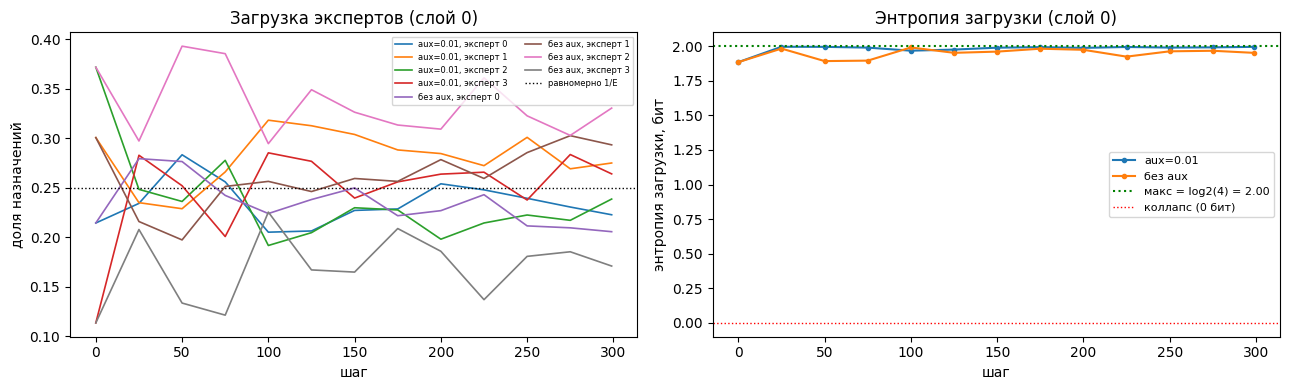

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def entropy(p):
    """Энтропия распределения p (в битах). Максимум = log2(E)."""
    p = np.asarray(p, dtype=float)
    p = p / p.sum()
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

E = 4
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for key in ["MoE top-2, aux=0.01", "MoE top-2, без aux"]:
    _, h = runs[key]
    steps = np.array([s for s, _, _ in h])
    loads0 = np.array([l[0] for _, _, l in h])
    ent = np.array([entropy(l) for l in loads0])

    # динамика загрузки первого слоя
    for e in range(E):
        ax[0].plot(steps, loads0[:, e], "-", lw=1.2,
                   label=f"{key.split(',')[-1].strip()}, эксперт {e}")
    ax[1].plot(steps, ent, "-o", lw=1.5, ms=3,
               label=key.split(",")[-1].strip())

ax[0].axhline(1/E, color="k", ls=":", lw=1, label="равномерно 1/E")
ax[0].set_xlabel("шаг"); ax[0].set_ylabel("доля назначений")
ax[0].set_title("Загрузка экспертов (слой 0)")
ax[0].legend(fontsize=6, ncol=2)

ax[1].axhline(np.log2(E), color="g", ls=":", lw=1.5, label=f"макс = log2({E}) = {np.log2(E):.2f}")
ax[1].axhline(0, color="r", ls=":", lw=1, label="коллапс (0 бит)")
ax[1].set_xlabel("шаг"); ax[1].set_ylabel("энтропия загрузки, бит")
ax[1].set_title("Энтропия загрузки (слой 0)")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(ARTIFACTS / "lab08_moe_load.png", dpi=150)
plt.show()

Специализация экспертов (доля токенов класса, ушедших к эксперту)
класс             E0     E1     E2     E3   
--------------------------------------------
строчная          0.24   0.27   0.28   0.20 
заглавная         0.28   0.07   0.65   0.00 
пробел            0.00   1.00   0.00   0.00 
перевод строки    0.00   0.00   0.00   1.00 
пунктуация        0.88   0.08   0.01   0.03 


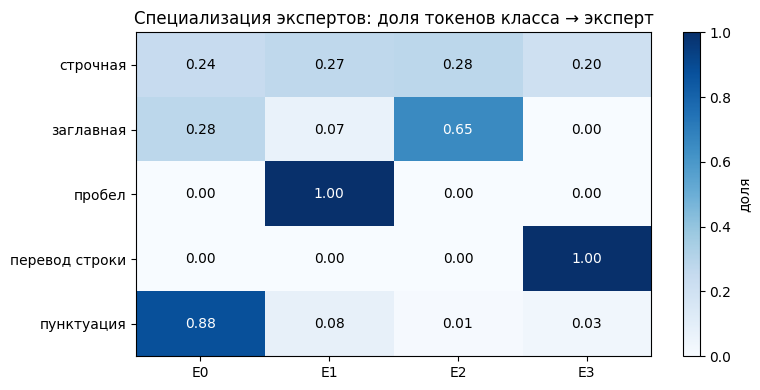

In [ ]:
# Классификация символов
def char_class(c):
    if c == " ": return "пробел"
    if c == "\n": return "перевод строки"
    if c.islower(): return "строчная"
    if c.isupper(): return "заглавная"
    if c.isdigit(): return "цифра"
    return "пунктуация"

classes = ["строчная", "заглавная", "пробел", "перевод строки", "пунктуация"]
E = 4

# Собираем top-1 назначения первого слоя MoE на валидации
@torch.no_grad()
def collect_assignments(model, data, n_batches=40):
    """Возвращает (chars: list[str], expert_ids: np.array)."""
    all_chars, all_e = [], []
    for _ in range(n_batches):
        x, _ = get_batch(data, T_CTX, BATCH)
        _ = model(x)
        # берём первый слой
        for b in model.blocks:
            if isinstance(b.mlp, MoE):
                topi = b.mlp.last_assign.cpu().numpy()
                top1 = topi[:, 0]
                all_e.append(top1)
                all_chars.extend(tok.decode(x.reshape(-1).cpu().tolist()))
                break
    return all_chars, np.concatenate(all_e)

# Берём модель с aux
model_aux = runs["MoE top-2, aux=0.01"][0]
model_aux.eval()
chars, assigns = collect_assignments(model_aux, val_data, n_batches=40)

# Строим таблицу: строки — классы, столбцы — эксперты
table = np.zeros((len(classes), E))
for c, e in zip(chars, assigns):
    cls = char_class(c)
    if cls in classes:
        table[classes.index(cls), e] += 1

# Нормируем по строкам: для каждого класса — доля токенов по экспертам
row_sums = table.sum(1, keepdims=True).clip(min=1)
table_norm = table / row_sums

# Печать таблицы
print("Специализация экспертов (доля токенов класса, ушедших к эксперту)")
print(f"{'класс':<16}" + "".join(f"  E{e}   " for e in range(E)))
print("-" * (16 + 7 * E))
for i, cls in enumerate(classes):
    print(f"{cls:<16}" + "".join(f"{table_norm[i, e]:6.2f} " for e in range(E)))

# график
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(table_norm, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(E)); ax.set_xticklabels([f"E{e}" for e in range(E)])
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
for i in range(len(classes)):
    for e in range(E):
        ax.text(e, i, f"{table_norm[i, e]:.2f}", ha="center", va="center",
                color="white" if table_norm[i, e] > 0.5 else "black", fontsize=10)
ax.set_title("Специализация экспертов: доля токенов класса → эксперт")
plt.colorbar(im, ax=ax, label="доля")
plt.tight_layout()
plt.savefig(ARTIFACTS / "lab08_moe_specialization.png", dpi=150)
plt.show()

## Вопросы

1. Выведите \(N_{opt}(C)\) из условия Лагранжа для задачи \(\min L(N,D)\) при \(6ND = C\).
2. Почему Kaplan et al. и Hoffmann et al. получили разные compute-optimal соотношения? Какой методологический фактор оказался главным?
3. Почему в практике (LLaMA и др.) малые модели обучают далеко за пределами compute-optimal числа токенов?
4. Почему без балансирующего loss роутинг коллапсирует? Опишите петлю положительной обратной связи.
5. Как сравнивать MoE и плотные модели: по активным параметрам, полным параметрам, FLOPs или памяти? Что выбирать для обучения и для инференса?